In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/semantic_ablation/source_snapshot.csv').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})


# Semantic context engineering

## tl;dr
S0–S3 isolate names and category labels on identical rows and values. S4–S5 test conventional cleaning; the audited source needs no numeric or category repair, so these are identity controls.

## Context & methods
Three paired 512-row contexts and one 128-row holdout were used. Targets and invoice IDs retain their original names. XGBoost receives one invariant encoded matrix across all semantic conditions. The original names are already fairly descriptive and there are no free-text fields.

In [2]:
import json
protocol=json.loads((ROOT/'data/semantic_ablation/protocol.json').read_text())
name_map=pd.DataFrame(protocol['names'].items(),columns=['original feature','enhanced feature'])
display(name_map)
for feature,mapping in protocol['categories'].items():
    print(feature); display(pd.DataFrame(mapping.items(),columns=['original value','enhanced value']))

,original feature,enhanced feature
0,invoice_amount_eur,invoice_amount_in_euros
1,payment_terms_days,invoice_payment_terms_in_days
2,customer_tenure_months,customer_relationship_duration_in_months
3,prior_late_payment_rate,customer_historical_late_payment_fraction
4,open_invoice_count,customer_current_open_invoice_count
5,customer_segment,customer_size_segment
6,region,customer_region
7,billing_address_mismatch,billing_address_mismatch_indicator
8,bank_account_changed_recently,recent_bank_account_change_indicator
9,weekend_submission,invoice_submitted_on_weekend_indicator


customer_segment


,original value,enhanced value
0,small,small customer segment
1,midmarket,midmarket customer segment
2,enterprise,enterprise customer segment


region


,original value,enhanced value
0,DACH,DACH region
1,Nordics,Nordic region
2,UK,United Kingdom region
3,Southern Europe,Southern European region


In [3]:
results=pd.read_csv(ROOT/'data/semantic_ablation/results.csv')
display(results.groupby(['model','condition','target'])[['f1','recall','balanced_accuracy','inference_seconds']].agg(['mean','std']).round(3))
display(results[results.model=='XGBoost'].groupby(['condition','target'])[['roc_auc','average_precision']].mean().round(3))

f1        recall        balanced_accuracy  \
                              mean    std   mean    std              mean   
model   condition target                                                    
SAP-RPT S0        is_fraud   0.000  0.000  0.000  0.000             0.497   
                  paid_late  0.592  0.004  0.601  0.011             0.658   
        S1        is_fraud   0.000  0.000  0.000  0.000             0.497   
                  paid_late  0.568  0.009  0.575  0.023             0.638   
        S2        is_fraud   0.000  0.000  0.000  0.000             0.497   
                  paid_late  0.571  0.017  0.575  0.030             0.643   
        S3        is_fraud   0.000  0.000  0.000  0.000             0.497   
                  paid_late  0.570  0.011  0.575  0.011             0.640   
        S4        is_fraud   0.000  0.000  0.000  0.000             0.497   
                  paid_late  0.592  0.004  0.601  0.011             0.658   
        S5        is_fraud   0.000  0.000  0.000  0.000             0.497   
                  paid_late  0.570  0.011  0.575  0.011             0.640   
XGBoost S0        is_fraud   0.149  0.136  0.125  0.125             0.551   
                  paid_late  0.572  0.073  0.621  0.111             0.631   
        S1        is_fraud   0.149  0.136  0.125  0.125             0.551   
                  paid_late  0.572  0.073  0.621  0.111             0.631   
        S2        is_fraud   0.149  0.136  0.125  0.125             0.551   
                  paid_late  0.572  0.073  0.621  0.111             0.631   
        S3        is_fraud   0.149  0.136  0.125  0.125             0.551   
                  paid_late  0.572  0.073  0.621  0.111             0.631   
        S4        is_fraud   0.149  0.136  0.125  0.125             0.551   
                  paid_late  0.572  0.073  0.621  0.111             0.631   
        S5        is_fraud   0.149  0.136  0.125  0.125             0.551   
                  paid_late  0.572  0.073  0.621  0.111             0.631   

                                   inference_seconds         
                               std              mean    std  
model   condition target                                     
SAP-RPT S0        is_fraud   0.002             0.574  0.211  
                  paid_late  0.003             0.574  0.211  
        S1        is_fraud   0.002             0.641  0.173  
                  paid_late  0.006             0.641  0.173  
        S2        is_fraud   0.002             0.674  0.066  
                  paid_late  0.011             0.674  0.066  
        S3        is_fraud   0.002             0.623  0.133  
                  paid_late  0.009             0.623  0.133  
        S4        is_fraud   0.002             0.598  0.131  
                  paid_late  0.003             0.598  0.131  
        S5        is_fraud   0.002             0.519  0.068  
                  paid_late  0.009             0.519  0.068  
XGBoost S0        is_fraud   0.054             0.001  0.000  
                  paid_late  0.058             0.001  0.000  
        S1        is_fraud   0.054             0.001  0.000  
                  paid_late  0.058             0.001  0.000  
        S2        is_fraud   0.054             0.001  0.000  
                  paid_late  0.058             0.001  0.000  
        S3        is_fraud   0.054             0.001  0.000  
                  paid_late  0.058             0.001  0.000  
        S4        is_fraud   0.054             0.001  0.000  
                  paid_late  0.058             0.001  0.000  
        S5        is_fraud   0.054             0.001  0.000  
                  paid_late  0.058             0.001  0.000

roc_auc  average_precision
condition target                               
S0        is_fraud     0.660              0.157
          paid_late    0.704              0.606
S1        is_fraud     0.660              0.157
          paid_late    0.704              0.606
S2        is_fraud     0.660              0.157
          paid_late    0.704              0.606
S3        is_fraud     0.660              0.157
          paid_late    0.704              0.606
S4        is_fraud     0.660              0.157
          paid_late    0.704              0.606
S5        is_fraud     0.660              0.157
          paid_late    0.704              0.606

In [4]:
validation_results=pd.read_csv(ROOT/'data/semantic_ablation/validation_results.csv')
display(validation_results.groupby(['target','condition'])[['f1','recall']].agg(['mean','std']).round(3))
print('Validation-selected:',{target: sub.groupby('condition').f1.mean().idxmax() for target,sub in validation_results.groupby('target')})

f1        recall       
                      mean    std   mean    std
target    condition                            
is_fraud  S0         0.133  0.115  0.074  0.064
          S1         0.133  0.115  0.074  0.064
          S2         0.133  0.115  0.074  0.064
          S3         0.133  0.115  0.074  0.064
paid_late S0         0.477  0.003  0.398  0.009
          S1         0.477  0.003  0.398  0.009
          S2         0.472  0.021  0.392  0.025
          S3         0.490  0.017  0.414  0.019

Validation-selected: {'is_fraud': 'S0', 'paid_late': 'S3'}


### Feature selection control
The generator's late-payment formula does not use `weekend_submission`; its fraud formula does not use `region`. A separate single-target request compares each feature removal with a matched single-target baseline. This is not mixed into S0–S5 because changing the target configuration would confound that ablation.

In [5]:
feature_results=pd.read_csv(ROOT/'data/semantic_ablation/feature_selection_results.csv')
display(feature_results.groupby(['target','condition'])[['f1','recall','accuracy','inference_seconds']].agg(['mean','std']).round(3))
feature_paired=feature_results.pivot_table(index=['seed','target'],columns='condition',values='f1')
print('Feature-removed minus matched baseline F1:')
display((feature_paired['feature_removed']-feature_paired['single_target_baseline']).round(3))

f1        recall        accuracy         \
                                   mean    std   mean    std     mean    std   
target    condition                                                            
is_fraud  feature_removed         0.000  0.000  0.000  0.000    0.935  0.005   
          single_target_baseline  0.000  0.000  0.000  0.000    0.932  0.005   
paid_late feature_removed         0.576  0.014  0.582  0.030    0.659  0.005   
          single_target_baseline  0.575  0.009  0.575  0.023    0.661  0.005   

                                 inference_seconds         
                                              mean    std  
target    condition                                        
is_fraud  feature_removed                    0.460  0.066  
          single_target_baseline             0.416  0.056  
paid_late feature_removed                    0.414  0.027  
          single_target_baseline             0.380  0.035

Feature-removed minus matched baseline F1:


seed  target   
11    is_fraud     0.000
      paid_late    0.008
23    is_fraud     0.000
      paid_late   -0.006
37    is_fraud     0.000
      paid_late    0.000
dtype: float64

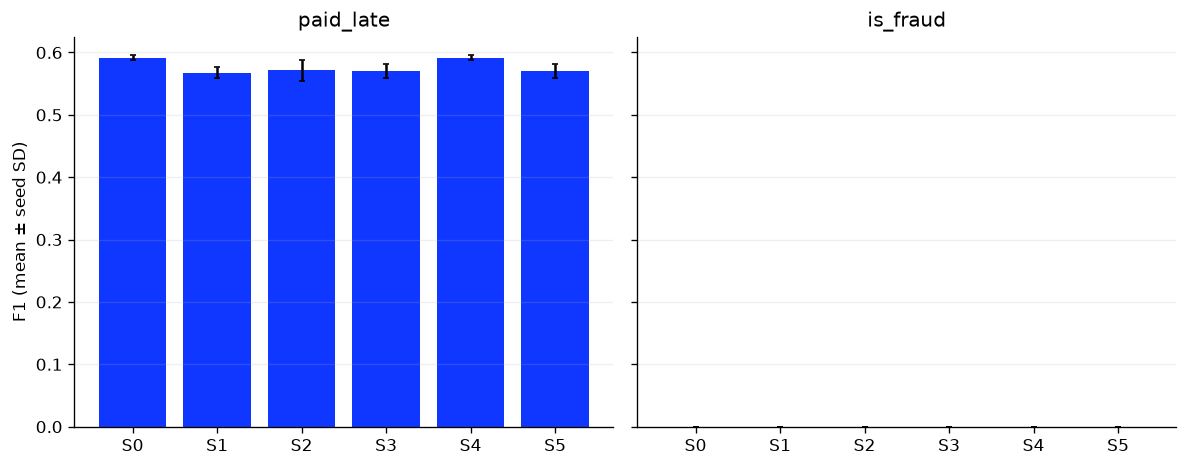

In [6]:
fig, axes=plt.subplots(1,2,figsize=(10,4),sharey=True)
for ax,target in zip(axes,['paid_late','is_fraud']):
    sub=results[(results.model=='SAP-RPT')&(results.target==target)].groupby('condition').f1.agg(['mean','std'])
    ax.bar(sub.index,sub['mean'],yerr=sub['std'].fillna(0),capsize=2,color='#0F37FF'); ax.set_title(target); ax.grid(axis='y',alpha=.2)
axes[0].set_ylabel('F1 (mean ± seed SD)'); plt.tight_layout(); plt.show()

In [7]:
paired=results[results.model=='SAP-RPT'].pivot_table(index=['seed','target'],columns='condition',values='f1')
for target in ['paid_late','is_fraud']:
    q=paired.xs(target,level='target')
    delta=q['S3']-q['S0']
    print(target,'S3-S0 paired F1:',delta.round(4).to_dict(),'mean',round(delta.mean(),4),'SD',round(delta.std(),4))
assert (paired['S0']==paired['S4']).all() and (paired['S3']==paired['S5']).all()
xgb=results[results.model=='XGBoost']; assert xgb.groupby(['seed','target']).f1.nunique().eq(1).all()

paid_late S3-S0 paired F1: {11: -0.0136, 23: -0.0251, 37: -0.0274} mean -0.022 SD 0.0074
is_fraud S3-S0 paired F1: {11: 0.0, 23: 0.0, 37: 0.0} mean 0.0 SD 0.0


In [8]:
for target in ['paid_late','is_fraud']:
    q=paired.xs(target,level='target')
    interaction=(q['S5']-q['S4'])-(q['S3']-q['S0'])
    print(target,'context-sample SD: S0',round(q['S0'].std(),4),'S3',round(q['S3'].std(),4),'cleaning × semantics interaction',interaction.round(4).tolist())

paid_late context-sample SD: S0 0.0041 S3 0.0112 cleaning × semantics interaction [0.0, 0.0, 0.0]
is_fraud context-sample SD: S0 0.0 S3 0.0 cleaning × semantics interaction [0.0, 0.0, 0.0]


In [9]:
from itertools import product
late=(paired.xs('paid_late',level='target')['S3']-paired.xs('paid_late',level='target')['S0']).to_numpy()
null_means=[np.mean(late*np.array(signs)) for signs in product([-1,1],repeat=len(late))]
p_value=np.mean(np.abs(null_means)>=abs(np.mean(late))-1e-12)
print('Exact paired sign-flip p value for late-payment S3-S0:',p_value,'(n=3; exploratory)')

Exact paired sign-flip p value for late-payment S3-S0: 0.25 (n=3; exploratory)


## Statistical interpretation
Three paired seeds give a descriptive effect and SD, not a reliable significance claim. Fraud has only eight holdout positives. S0=S4 and S3=S5 by design because cleaning changed no source values. Validation favored S3 for late payment, but its gain reversed on holdout. Any semantic effect is distinct from context selection because every seed uses identical context IDs and size across S0–S5.

## Does Semantic Context Improve SAP-RPT Predictions?
The paired table and plot above are the actual SAP deployment measurements. Descriptive names and category labels did not produce a robust positive effect here. The cleaning controls are identical to raw data, so they cannot quantify a cleaning gain. Context selection was evaluated independently in notebooks 02–03. **SAP TechEd 2026 conclusion:** the available evidence favors careful context composition over a claim that renaming these already descriptive invoice fields improves prediction quality.